In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from matplotlib import pyplot as plt
import seaborn as sns
from cartopy import feature as cf
from cartopy import crs as ccrs
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import rgb2hex
from matplotlib.colors import to_rgb
from generativepy.color import Color
from PIL import ImageColor
from tqdm import tqdm
from pathlib import Path

In [2]:
names = locals()

In [3]:
ROOT    = Path('..')
DATA    = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'

In [4]:
country_raster_50km_ = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-50km.tif')
country_raster_50km = country_raster_50km_.read(1)

In [5]:
country_pseudo_values = pd.read_csv(DATA / 'country-pseudo-values.csv')
df_cement_production = pd.read_csv(DATA / 'production-142.csv', index_col=0)
economies_142 = df_cement_production.columns.tolist()

In [6]:
world_map      = gpd.read_file(DATA / 'simplified-world-map/world-map.shp')
world_map      = world_map.drop([31])
world_map_eck4 = world_map.to_crs('ESRI:54012')

compile results for aggregate extraction

In [7]:
def compile_all_country_extraction(scenario, the_var):
    # Correct aggregation: sum the raw Monte-Carlo draws across economies FIRST
    # (keeping the draw axis); percentiles are taken only at the end, in the cell
    # that builds `extraction_reduction`. Summing per-economy percentiles (the old
    # approach) assumes every economy hits its extreme in the same draw and
    # overstates the global interval.
    RESULTS = Path(r'F:\aggregates-mining-biodiversity\results')
    global_draws = None
    for economy in tqdm(economies_142):
        a_path = RESULTS / 'material-flows' / economy / scenario / f'{the_var}.npz'
        value_array = np.load(a_path)['data'].astype(np.float64)   # (n_sim, n_years)
        global_draws = value_array if global_draws is None else global_draws + value_array
    return global_draws   # (n_sim, n_years), summed over economies

In [8]:
def compile_all_country_reduction(scenario, the_var):
    # Paired reduction (BAU - scenario) per Monte-Carlo draw, summed across
    # economies in draw space; percentiles are taken later. Linear, so this equals
    # global_BAU_draws - global_scenario_draws.
    RESULTS = Path(r'F:\aggregates-mining-biodiversity\results')
    global_diff = None
    for economy in tqdm(economies_142):
        path_1 = RESULTS / 'material-flows' / economy / 'BAU' / f'{the_var}.npz'
        path_2 = RESULTS / 'material-flows' / economy / scenario / f'{the_var}.npz'
        d = np.load(path_1)['data'].astype(np.float64) - np.load(path_2)['data'].astype(np.float64)
        global_diff = d if global_diff is None else global_diff + d
    return global_diff   # (n_sim, n_years), summed over economies

In [9]:
sand_extraction_BAU = compile_all_country_extraction('BAU', 'sand_extraction')
sand_extraction_MIU = compile_all_country_extraction('MIU', 'sand_extraction')
sand_extraction_LE  = compile_all_country_extraction('LE', 'sand_extraction')
sand_extraction_RE  = compile_all_country_extraction('RE', 'sand_extraction')
sand_extraction_RC  = compile_all_country_extraction('RC', 'sand_extraction')
sand_extraction_SS  = compile_all_country_extraction('SS', 'sand_extraction')
sand_extraction_CCR = compile_all_country_extraction('CCR', 'sand_extraction')
sand_extraction_CE  = compile_all_country_extraction('CE', 'sand_extraction')

100%|██████████| 142/142 [00:04<00:00, 31.78it/s]


In [10]:
gravel_extraction_BAU = compile_all_country_extraction('BAU', 'gravel_extraction')
gravel_extraction_MIU = compile_all_country_extraction('MIU', 'gravel_extraction')
gravel_extraction_LE  = compile_all_country_extraction('LE', 'gravel_extraction')
gravel_extraction_RE  = compile_all_country_extraction('RE', 'gravel_extraction')
gravel_extraction_RC  = compile_all_country_extraction('RC', 'gravel_extraction')
gravel_extraction_SS  = compile_all_country_extraction('SS', 'gravel_extraction')
gravel_extraction_CCR = compile_all_country_extraction('CCR', 'gravel_extraction')
gravel_extraction_CE  = compile_all_country_extraction('CE', 'gravel_extraction')

100%|██████████| 142/142 [00:04<00:00, 30.48it/s]


In [11]:
limestone_extraction_BAU = compile_all_country_extraction('BAU', 'limestone_extraction')
limestone_extraction_MIU = compile_all_country_extraction('MIU', 'limestone_extraction')
limestone_extraction_LE  = compile_all_country_extraction('LE', 'limestone_extraction')
limestone_extraction_RE  = compile_all_country_extraction('RE', 'limestone_extraction')
limestone_extraction_RC  = compile_all_country_extraction('RC', 'limestone_extraction')
limestone_extraction_SS  = compile_all_country_extraction('SS', 'limestone_extraction')
limestone_extraction_CCR = compile_all_country_extraction('CCR', 'limestone_extraction')
limestone_extraction_CE  = compile_all_country_extraction('CE', 'limestone_extraction')

100%|██████████| 142/142 [00:05<00:00, 28.08it/s]


In [12]:
sand_extraction_reduction_BAU = compile_all_country_reduction('BAU', 'sand_extraction')
sand_extraction_reduction_MIU = compile_all_country_reduction('MIU', 'sand_extraction')
sand_extraction_reduction_LE  = compile_all_country_reduction('LE', 'sand_extraction')
sand_extraction_reduction_RE  = compile_all_country_reduction('RE', 'sand_extraction')
sand_extraction_reduction_RC  = compile_all_country_reduction('RC', 'sand_extraction')
sand_extraction_reduction_SS  = compile_all_country_reduction('SS', 'sand_extraction')
sand_extraction_reduction_CCR = compile_all_country_reduction('CCR', 'sand_extraction')
sand_extraction_reduction_CE  = compile_all_country_reduction('CE', 'sand_extraction')

100%|██████████| 142/142 [00:01<00:00, 116.59it/s]


In [13]:
gravel_extraction_reduction_BAU = compile_all_country_reduction('BAU', 'gravel_extraction')
gravel_extraction_reduction_MIU = compile_all_country_reduction('MIU', 'gravel_extraction')
gravel_extraction_reduction_LE  = compile_all_country_reduction('LE', 'gravel_extraction')
gravel_extraction_reduction_RE  = compile_all_country_reduction('RE', 'gravel_extraction')
gravel_extraction_reduction_RC  = compile_all_country_reduction('RC', 'gravel_extraction')
gravel_extraction_reduction_SS  = compile_all_country_reduction('SS', 'gravel_extraction')
gravel_extraction_reduction_CCR = compile_all_country_reduction('CCR', 'gravel_extraction')
gravel_extraction_reduction_CE  = compile_all_country_reduction('CE', 'gravel_extraction')

100%|██████████| 142/142 [00:01<00:00, 116.29it/s]


In [14]:
limestone_extraction_reduction_BAU = compile_all_country_reduction('BAU', 'limestone_extraction')
limestone_extraction_reduction_MIU = compile_all_country_reduction('MIU', 'limestone_extraction')
limestone_extraction_reduction_LE  = compile_all_country_reduction('LE', 'limestone_extraction')
limestone_extraction_reduction_RE  = compile_all_country_reduction('RE', 'limestone_extraction')
limestone_extraction_reduction_RC  = compile_all_country_reduction('RC', 'limestone_extraction')
limestone_extraction_reduction_SS  = compile_all_country_reduction('SS', 'limestone_extraction')
limestone_extraction_reduction_CCR = compile_all_country_reduction('CCR', 'limestone_extraction')
limestone_extraction_reduction_CE  = compile_all_country_reduction('CE', 'limestone_extraction')

100%|██████████| 142/142 [00:01<00:00, 105.54it/s]


In [15]:
total_extraction_BAU = sand_extraction_BAU + gravel_extraction_BAU + limestone_extraction_BAU
total_extraction_MIU = sand_extraction_MIU + gravel_extraction_MIU + limestone_extraction_MIU
total_extraction_LE  = sand_extraction_LE  + gravel_extraction_LE  + limestone_extraction_LE
total_extraction_RE  = sand_extraction_RE  + gravel_extraction_RE  + limestone_extraction_RE
total_extraction_RC  = sand_extraction_RC  + gravel_extraction_RC  + limestone_extraction_RC
total_extraction_SS  = sand_extraction_SS  + gravel_extraction_SS  + limestone_extraction_SS
total_extraction_CCR = sand_extraction_CCR + gravel_extraction_CCR + limestone_extraction_CCR
total_extraction_CE  = sand_extraction_CE  + gravel_extraction_CE  + limestone_extraction_CE

In [16]:
total_reduction_BAU = sand_extraction_reduction_BAU + gravel_extraction_reduction_BAU + limestone_extraction_reduction_BAU
total_reduction_MIU = sand_extraction_reduction_MIU + gravel_extraction_reduction_MIU + limestone_extraction_reduction_MIU
total_reduction_LE  = sand_extraction_reduction_LE  + gravel_extraction_reduction_LE  + limestone_extraction_reduction_LE
total_reduction_RE  = sand_extraction_reduction_RE  + gravel_extraction_reduction_RE  + limestone_extraction_reduction_RE
total_reduction_RC  = sand_extraction_reduction_RC  + gravel_extraction_reduction_RC  + limestone_extraction_reduction_RC
total_reduction_SS  = sand_extraction_reduction_SS  + gravel_extraction_reduction_SS  + limestone_extraction_reduction_SS
total_reduction_CCR = sand_extraction_reduction_CCR + gravel_extraction_reduction_CCR + limestone_extraction_reduction_CCR
total_reduction_CE  = sand_extraction_reduction_CE  + gravel_extraction_reduction_CE  + limestone_extraction_reduction_CE

In [17]:
extraction_reduction = pd.DataFrame([], index=['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE'], columns=['sand_l', 'sand', 'sand_u', 'gravel_l', 'gravel', 'gravel_u', 'limestone_l', 'limestone', 'limestone_u', 'total_l', 'total', 'total_u', 'reduction_l', 'reduction', 'reduction_u'])

# Percentiles are taken HERE, after the per-draw global series have been summed
# over economies (compile_*) and over materials (total_*). Cumulative 2023-2050 =
# sum over years (axis=1) per draw, then 2.5 / 50 / 97.5 percentiles over draws.
for material in ['sand', 'gravel', 'limestone', 'total']:
    for scenario in ['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE']:
        cumulative_draws = np.sum(names[f'{material}_extraction_{scenario}'], axis=1)   # (n_sim,)
        extraction_reduction.loc[scenario, [f'{material}_l', material, f'{material}_u']] = np.percentile(cumulative_draws, [2.5, 50, 97.5]) / 1e6

for scenario in ['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE']:
    cumulative_reduction_draws = np.sum(names[f'total_reduction_{scenario}'], axis=1)   # (n_sim,)
    extraction_reduction.loc[scenario, ['reduction_l', 'reduction', 'reduction_u']] = np.percentile(cumulative_reduction_draws, [2.5, 50, 97.5]) / 1e6

In [18]:
RESULTS = ROOT / 'results'
extraction_reduction.to_csv(RESULTS / 'Data-for-Fig-2a.csv')

In [19]:
for material in ['sand', 'gravel', 'limestone']:
    for scenario in ['BAU', 'CE']:
        # names[f'{material}_demand_2023_2050_{scenario}_50km'] = rio.open(f'../results/demand-rasters/{material}-demand-2023-2050-{scenario}-50km.tif').read(1)
        names[f'{material}_demand_2023_2050_{scenario}_50km'] = rio.open(RESULTS / 'extraction-rasters' / f'{material}-extraction-demand-2023-2050-{scenario}-50km-M.tif').read(1)

total_demand_2023_2050_BAU_50km = sand_demand_2023_2050_BAU_50km + gravel_demand_2023_2050_BAU_50km + limestone_demand_2023_2050_BAU_50km
total_demand_2023_2050_CE_50km  = sand_demand_2023_2050_CE_50km + gravel_demand_2023_2050_CE_50km + limestone_demand_2023_2050_CE_50km


absolute_reduction = {}
percent_reduction  = {}
country_ids = np.unique(country_raster_50km)[1:]
for i in country_ids:
    country_demand_BAU = total_demand_2023_2050_BAU_50km[country_raster_50km == i].sum()
    country_demand_CE  = total_demand_2023_2050_CE_50km[country_raster_50km == i].sum()

    if country_demand_BAU != 0:
        aa = (country_demand_BAU - country_demand_CE) / 1e6    # unit: Mt
        bb = 100 * (country_demand_BAU - country_demand_CE) / country_demand_BAU
        absolute_reduction.update({i: aa})
        percent_reduction.update({i:bb})


for i in country_ids:
    iso3 = country_pseudo_values[country_pseudo_values['value'] == i]['country'].values[0]
    idx = world_map_eck4[world_map_eck4['GID_0'] == iso3].index[0]
    try:
        world_map_eck4.loc[idx, 'absolute reduction'] = absolute_reduction[i]
        world_map_eck4.loc[idx, 'percent reduction'] = percent_reduction[i]
        # print(i, iso3, idx)
    except:
        pass

In [20]:
# abs_bins = [0, 1e2, 1e3, 1e4, 1e5]
abs_bins = [0, 1e2, 5e3, 1e5]
pct_bins = [13, 25, 35, 48]
abs_labels = [1, 2, 3]   # 代表 4 档
pct_labels = [1, 2, 3]

# ===== 2. fixed-interval grouping =====
world_map_eck4['abs_group'] = pd.cut(
    world_map_eck4['absolute reduction'],
    bins=abs_bins,
    labels=abs_labels,
    include_lowest=True
).astype("float")

world_map_eck4['pct_group'] = pd.cut(
    world_map_eck4['percent reduction'],
    bins=pct_bins,
    labels=pct_labels,
    include_lowest=True
).astype("float")

# ===== 3. fill NA with 0 =====
world_map_eck4['abs_group'] = world_map_eck4['abs_group'].fillna(0).astype(int)
world_map_eck4['pct_group'] = world_map_eck4['pct_group'].fillna(0).astype(int)

# ===== 4. combine into group_16 =====
world_map_eck4['group_9'] = np.where(
    (world_map_eck4['abs_group'] > 0) & (world_map_eck4['pct_group'] > 0),
    (world_map_eck4['abs_group'] - 1) * 3 + world_map_eck4['pct_group'],
    np.nan
)

compile results for mining area

In [21]:
mining_area_reduction = pd.DataFrame([], index=['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE'], columns=['total_l', 'total', 'total_u', 'reduction', 'reduction_l', 'reduction_u'])

all_mining_areas = []

for scenario in ['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE']:
    a_scenario_mining_areas = []
    for L_1 in ['L', 'M', 'H']:
        for L_2 in ['L', 'M', 'H']:
            for L_3 in ['L', 'M', 'H']:
                mining_area_array = rio.open(RESULTS / 'mining-area' / f'mining-area-expansion-2050-{scenario}-B0.00-50km-D{L_1}-R{L_2}-A{L_3}.tif').read(1)
                a_scenario_mining_areas.append(np.sum(mining_area_array))

                if (L_1 == 'M') and (L_2 == 'M') and (L_3 == 'M'):
                    mining_area_reduction.loc[scenario, 'total'] = np.sum(mining_area_array)
                    mining_area_reduction.loc[scenario, 'reduction'] = mining_area_reduction.loc['BAU', 'total'] - np.sum(mining_area_array)
    
    mining_area_reduction.loc[scenario, 'total_l'] = min(a_scenario_mining_areas)
    mining_area_reduction.loc[scenario, 'total_u'] = max(a_scenario_mining_areas)

    all_mining_areas.append(a_scenario_mining_areas)
    a_scenario_reduction = [aa - bb for aa, bb in zip(all_mining_areas[0], a_scenario_mining_areas)]

    mining_area_reduction.loc[scenario, 'reduction_l'] = min(a_scenario_reduction)
    mining_area_reduction.loc[scenario, 'reduction_u'] = max(a_scenario_reduction)

In [22]:
mining_area_reduction.to_csv(RESULTS / 'Data-for-Fig-2c.csv')

In [23]:
mining_area_expansion_2050_BAU_50km = rio.open(RESULTS / 'mining-area' / 'mining-area-expansion-2050-BAU-B0.00-50km-DM-RM-AM.tif').read(1)
mining_area_expansion_2050_CE_50km  = rio.open(RESULTS / 'mining-area' / 'mining-area-expansion-2050-CE-B0.00-50km-DM-RM-AM.tif').read(1)

In [24]:
mining_area_reduction_CE_50km = mining_area_expansion_2050_BAU_50km - mining_area_expansion_2050_CE_50km

compile results for affected species range (ASR)

In [25]:
mining_biodiversity_overlap_reduction = pd.DataFrame([], index=['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE'], columns=['total_l', 'total', 'total_u', 'reduction', 'reduction_l', 'reduction_u'])

all_mining_biodiversity_overlaps = []
for scenario in ['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE']:
    a_scenario_mining_biodiversity_overlaps = []
    for L_1 in ['L', 'M', 'H']:
        for L_2 in ['L', 'M', 'H']:
            for L_3 in ['L', 'M', 'H']:
                mining_biodiversity_overlap_array = rio.open(RESULTS / 'biodiversity-risk' / f'mining-biodiversity-overlap-2050-{scenario}-B0.00-50km-D{L_1}-R{L_2}-A{L_3}.tif').read(1)
                a_scenario_mining_biodiversity_overlaps.append(np.sum(mining_biodiversity_overlap_array))

                if (L_1 == 'M') and (L_2 == 'M') and (L_3 == 'M'):
                    mining_biodiversity_overlap_reduction.loc[scenario, 'total'] = np.sum(mining_biodiversity_overlap_array)
                    mining_biodiversity_overlap_reduction.loc[scenario, 'reduction'] = mining_biodiversity_overlap_reduction.loc['BAU', 'total'] - np.sum(mining_biodiversity_overlap_array)
    
    mining_biodiversity_overlap_reduction.loc[scenario, 'total_l'] = min(a_scenario_mining_biodiversity_overlaps)
    mining_biodiversity_overlap_reduction.loc[scenario, 'total_u'] = max(a_scenario_mining_biodiversity_overlaps)

    all_mining_biodiversity_overlaps.append(a_scenario_mining_biodiversity_overlaps)
    a_scenario_reduction = [aa - bb for aa, bb in zip(all_mining_biodiversity_overlaps[0], a_scenario_mining_biodiversity_overlaps)]

    mining_biodiversity_overlap_reduction.loc[scenario, 'reduction_l'] = min(a_scenario_reduction)
    mining_biodiversity_overlap_reduction.loc[scenario, 'reduction_u'] = max(a_scenario_reduction)    


In [26]:
mining_biodiversity_overlap_reduction.to_csv(RESULTS / 'Data-for-Fig-2e.csv')

In [27]:
mining_biodiversity_overlap_2050_BAU_50km = rio.open(RESULTS / 'biodiversity-risk' / 'mining-biodiversity-overlap-2050-BAU-B0.00-50km-DM-RM-AM.tif').read(1)
mining_biodiversity_overlap_2050_CE_50km  = rio.open(RESULTS / 'biodiversity-risk' / 'mining-biodiversity-overlap-2050-CE-B0.00-50km-DM-RM-AM.tif').read(1)

In [28]:
overlap_reduction_CE_50km = mining_biodiversity_overlap_2050_BAU_50km - mining_biodiversity_overlap_2050_CE_50km

## draw Fig.2

In [29]:
def make_colorlist(c00_, c01_, c10_, c11_, num_grps):
    ### get corner colors from https://www.joshuastevens.net/cartography/make-a-bivariate-choropleth-map/
    def _hex_to_Color(hexcode):
        rgb = ImageColor.getcolor(hexcode, 'RGB')
        rgb = [v/256 for v in rgb]
        rgb = Color(*rgb)
        return rgb
    
    c00 = _hex_to_Color(c00_)
    c10 = _hex_to_Color(c10_)
    c01 = _hex_to_Color(c01_)
    c11 = _hex_to_Color(c11_)
    
    ### now create square grid of colors, using color interpolation from generativepy package
    c00_to_c10 = []
    c01_to_c11 = []
    colorlist = []
    for i in range(num_grps):
        c00_to_c10.append(c00.lerp(c10, 1/(num_grps-1) * i))
        c01_to_c11.append(c01.lerp(c11, 1/(num_grps-1) * i))
    for i in range(num_grps):
        for j in range(num_grps):
            colorlist.append(c00_to_c10[i].lerp(c01_to_c11[i], 1/(num_grps-1) * j))
    
    ### convert back to hex color
    colorlist = [rgb2hex([c.r, c.g, c.b]) for c in colorlist]

    return colorlist

In [30]:
colorlist_1 = make_colorlist('#e8e8e8', '#64acbe', '#c85a5a', '#574249', 3)
colorlist_2 = make_colorlist('#e8e8e8', '#5ac8c8', '#be64ac', '#3b4994', 3)
colorlist_3 = make_colorlist('#e8e8e8', '#6c83b5', '#73ae80', '#2a5a5b', 3)
colorlist_4 = make_colorlist('#e8e8e8', '#c8b35a', '#9972af', '#804d36', 3)
colorlist_5 = make_colorlist('#EDE7F2', '#5AA5DC', '#CD595C', '#631676', 3)

In [31]:
values = [i+1 for i in range(9)]
custom_cmap1 = LinearSegmentedColormap.from_list('custom_cmap1', colorlist_1)
custom_cmap2 = LinearSegmentedColormap.from_list('custom_cmap2', colorlist_2)
custom_cmap3 = LinearSegmentedColormap.from_list('custom_cmap3', colorlist_3)
custom_cmap4 = LinearSegmentedColormap.from_list('custom_cmap4', colorlist_4)
custom_cmap5 = LinearSegmentedColormap.from_list('custom_cmap5', colorlist_5)

In [32]:
def draw_the_patch(axx, n, colorlist):
    cax1 = axx.inset_axes([0.7, 0.07, 0.10, 0.15])
    cax1.set_aspect('equal')
    num_grps = n
    cax1.set_xlim(0, num_grps)
    cax1.set_ylim(0, num_grps)
    for i in range(num_grps):
        for j in range(num_grps):
            index = i * num_grps + j
            color = colorlist[i * num_grps + j]
            rect = plt.Rectangle([j, i], 1, 1, color=color)  # Flip the vertical axis
            cax1.add_patch(rect)    

    cax1.set_xticks([0.5, 1.5, 2.5])
    cax1.set_xticklabels(['13-25%', '25-35%', '35-48%'], fontsize=8, rotation=90)

    cax1.set_yticks([0.5, 1.5, 2.5])
    cax1.set_yticklabels(['<0.1 Gt', '0.1-5 Gt', '> 5Gt'], fontsize=8, rotation=0)
    cax1.tick_params(length=0)

    cax1.set_ylabel('Absolute\nreduction', fontsize=8)
    cax1.set_xlabel('Percent reduction', fontsize=8)

In [33]:
def draw_the_background(axx):
    nodata_area = world_map_eck4[world_map_eck4['GID_0'].isin(['CAF', 'SSD', 'ESH', 'SWZ', 'LSO', 'GRL'])]
    world_map_eck4.plot(color='whitesmoke', edgecolor='k', lw=0.0, ax=axx, zorder=0)
    world_map_eck4.plot(color='none', edgecolor='lightgrey', lw=0.3, ax=axx, zorder=10)
    nodata_area.plot(hatch='////', linewidth=0.5, color='none', edgecolor='grey', zorder=15, ax=axx)
    axx.set_ylim(-6.6e6, 8.6e6)
    axx.axis('off')

    cax1 = axx.inset_axes([0.40, 0.05, 0.02, 0.03]) 
    cax1.add_patch(Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='grey', hatch='////'))
    cax1.axis('off')
    cax1.text(1.2, 0.0, 'No data', fontsize=9)


In [34]:
display_extent_50km = [country_raster_50km_.bounds.left, country_raster_50km_.bounds.right, country_raster_50km_.bounds.bottom, country_raster_50km_.bounds.top]

In [35]:
# 自定义科学计数格式
def sci_fmt(x, pos):
    if x == 0:
        return "0"
    s = f"{x:.0e}"
    base, exp = s.split('e')
    return f"{base}×10$^{{{int(exp)}}}$"

In [36]:
# xtick_labels = ['Business-as-usual (BAU)', 'Lifetime extension', 'Component use', 'Clinker substitution', 'End-of-life recycling', 'Sand substitution', 'More intensive use', 'Circular economy (CE)']
xtick_labels = ['BAU', 'Lifetime extension', 'Component use', 'Clinker substitution', 'End-of-life recycling', 'Sand substitution', 'More intensive use', 'CE']

In main text

In [49]:
g_1 = extraction_reduction.loc['MIU', 'reduction']
g_2 = extraction_reduction.loc['MIU', 'reduction_l']
g_3 = extraction_reduction.loc['MIU', 'reduction_u']

g_4 = extraction_reduction.loc['LE', 'reduction']
g_5 = extraction_reduction.loc['LE', 'reduction_l']
g_6 = extraction_reduction.loc['LE', 'reduction_u']

g_7 = extraction_reduction.loc['SS', 'reduction']
g_8 = extraction_reduction.loc['SS', 'reduction_l']
g_9 = extraction_reduction.loc['SS', 'reduction_u']

g_10 = extraction_reduction.loc['CCR', 'reduction']
g_11 = extraction_reduction.loc['CCR', 'reduction_l']
g_12 = extraction_reduction.loc['CCR', 'reduction_u']

g_13 = extraction_reduction.loc['RC', 'reduction']
g_14 = extraction_reduction.loc['RC', 'reduction_l']
g_15 = extraction_reduction.loc['RC', 'reduction_u']

g_16 = extraction_reduction.loc['RE', 'reduction']
g_17 = extraction_reduction.loc['RE', 'reduction_l']
g_18 = extraction_reduction.loc['RE', 'reduction_u']

print(f'More intensive use, implemented as a 5% reduction in per-capita in-use stock, yields the largest single reduction, \n\
lowering cumulative extraction by {g_1:.0f} Gt (95% CI: {g_2:.0f}-{g_3:.0f} Gt); \
extending the lifetime of buildings and infrastructure by 50% further reduces cumulative extraction by {g_4:.0f} Gt (95% CI: {g_5:.0f}-{g_6:.0f} Gt) (Figure 2a).')
print(f'Material substitution also exhibits substantial mitigation potential. \n\
Replacing 20% of virgin sand with ore-sand decreases cumulative extraction by {g_7:.1f} Gt (95% CI: {g_8:.1f}-{g_9:.1f} Gt), \n\
while reducing the clinker-to-cement ratio by 25% avoids an additional {g_10:.1f} Gt (95% CI: {g_11:.0f}-{g_12:.0f} Gt) of limestone extraction (Figure 2a).')
print('Measures targeting material recovery contribute further reductions.')
print(f'End-of-life recycling, assuming recovery of 20% of coarse aggregate outflows, \n\
reduces cumulative extraction by {g_13:.1f} Gt (95% CI: {g_14:.1f}-{g_15:.1f} Gt), \n\
whereas component reuse—directly reusing 10% of outflows—lowers extraction by {g_16:.0f} Gt (95% CI: {g_17:.0f}-{g_18:.0f} Gt) (Figure 2a).')

More intensive use, implemented as a 5% reduction in per-capita in-use stock, yields the largest single reduction, 
lowering cumulative extraction by 27 Gt (95% CI: 26-28 Gt); extending the lifetime of buildings and infrastructure by 50% further reduces cumulative extraction by 9 Gt (95% CI: 6-12 Gt) (Figure 2a).
Material substitution also exhibits substantial mitigation potential. 
Replacing 20% of virgin sand with ore-sand decreases cumulative extraction by 10.0 Gt (95% CI: 9.9-10.1 Gt), 
while reducing the clinker-to-cement ratio by 25% avoids an additional 10.7 Gt (95% CI: 0-21 Gt) of limestone extraction (Figure 2a).
Measures targeting material recovery contribute further reductions.
End-of-life recycling, assuming recovery of 20% of coarse aggregate outflows, 
reduces cumulative extraction by 25.3 Gt (95% CI: 24.5-26.2 Gt), 
whereas component reuse—directly reusing 10% of outflows—lowers extraction by 17 Gt (95% CI: 16-18 Gt) (Figure 2a).


In [38]:
h_0 = 100 * (extraction_reduction.loc['BAU', 'total'] - extraction_reduction.loc['CE', 'total']) / extraction_reduction.loc['BAU', 'total']
h_1 = extraction_reduction.loc['BAU', 'total']
h_2 = extraction_reduction.loc['BAU', 'total_l']
h_3 = extraction_reduction.loc['BAU', 'total_u']
h_4 = extraction_reduction.loc['CE', 'total']
h_5 = extraction_reduction.loc['CE', 'total_l']
h_6 = extraction_reduction.loc['CE', 'total_u']

h_7 = extraction_reduction.loc['BAU', 'sand']
h_8 = extraction_reduction.loc['BAU', 'sand_l']
h_9 = extraction_reduction.loc['BAU', 'sand_u']
h_10 = extraction_reduction.loc['CE', 'sand']
h_11 = extraction_reduction.loc['CE', 'sand_l']
h_12 = extraction_reduction.loc['CE', 'sand_u']

h_13 = extraction_reduction.loc['BAU', 'gravel']
h_14 = extraction_reduction.loc['BAU', 'gravel_l']
h_15 = extraction_reduction.loc['BAU', 'gravel_u']
h_16 = extraction_reduction.loc['CE', 'gravel']
h_17 = extraction_reduction.loc['CE', 'gravel_l']
h_18 = extraction_reduction.loc['CE', 'gravel_u']

h_19 = extraction_reduction.loc['BAU', 'limestone']
h_20 = extraction_reduction.loc['BAU', 'limestone_l']
h_21 = extraction_reduction.loc['BAU', 'limestone_u']
h_22 = extraction_reduction.loc['CE', 'limestone']
h_23 = extraction_reduction.loc['CE', 'limestone_l']
h_24 = extraction_reduction.loc['CE', 'limestone_u']

h_25 = world_map_eck4[world_map_eck4['GID_0'] == 'USA']['absolute reduction'].values[0] / 1e3
h_26 = world_map_eck4[world_map_eck4['GID_0'] == 'USA']['percent reduction'].values[0]
h_27 = world_map_eck4[world_map_eck4['GID_0'] == 'ESP']['absolute reduction'].values[0] / 1e3
h_28 = world_map_eck4[world_map_eck4['GID_0'] == 'ESP']['percent reduction'].values[0]
h_29 = world_map_eck4[world_map_eck4['GID_0'] == 'ITA']['absolute reduction'].values[0] / 1e3
h_30 = world_map_eck4[world_map_eck4['GID_0'] == 'ITA']['percent reduction'].values[0]


print(f'When implemented jointly, cumulative global extraction over 2023-2050 declines by {h_0:.0f}%, \n\
from {h_1:.0f} Gt (95% CI: {h_2:.0f}-{h_3:.0f} Gt) under BAU to {h_4:.0f} Gt (95% CI: {h_5:.0f}-{h_6:.0f} Gt) under CE (Figure 2a).')
print(f'Reductions are observed across all major material categories: sand extraction decreases from {h_7:.0f} Gt (95% CI: {h_8:.0f}-{h_9:.0f} Gt) to {h_10:.0f} Gt (95% CI: {h_11:.0f}-{h_12:.0f} Gt), \n\
gravel from {h_13:.0f} Gt (95% CI: {h_14:.0f}-{h_15:.0f} Gt) to {h_16:.0f} Gt (95% CI: {h_17:.0f}-{h_18:.0f} Gt), and limestone used for cement production from {h_19:.0f} Gt (95% CI: {h_20:.0f}-{h_21:.0f} Gt) to {h_22:.0f} Gt (95% CI: {h_23:.0f}-{h_24:.0f} Gt). ')
print(f'Significant reductions are also observed in high-income regions with large existing stocks, including the United States ({h_25:.1f} Gt; {h_26:.0f}%), Spain ({h_27:.1f} Gt; {h_28:.0f}%) and Italy ({h_29:.1f} Gt; {h_30:.0f}%).')

When implemented jointly, cumulative global extraction over 2023-2050 declines by 21%, 
from 447 Gt (95% CI: 422-469 Gt) under BAU to 353 Gt (95% CI: 339-364 Gt) under CE (Figure 2a).
Reductions are observed across all major material categories: sand extraction decreases from 207 Gt (95% CI: 203-212 Gt) to 161 Gt (95% CI: 158-164 Gt), 
gravel from 146 Gt (95% CI: 141-150 Gt) to 118 Gt (95% CI: 115-122 Gt), and limestone used for cement production from 94 Gt (95% CI: 71-113 Gt) to 74 Gt (95% CI: 62-82 Gt). 
Significant reductions are also observed in high-income regions with large existing stocks, including the United States (4.1 Gt; 29%), Spain (0.8 Gt; 39%) and Italy (1.1 Gt; 33%).


In [39]:
j_0 = (mining_area_reduction.loc['BAU', 'total'] - mining_area_reduction.loc['CE', 'total']) / mining_area_reduction.loc['BAU', 'total']
j_1 = mining_area_reduction.loc['BAU', 'total']
j_2 = mining_area_reduction.loc['BAU', 'total_l']
j_3 = mining_area_reduction.loc['BAU', 'total_u']
j_4 = mining_area_reduction.loc['CE', 'total']
j_5 = mining_area_reduction.loc['CE', 'total_l']
j_6 = mining_area_reduction.loc['CE', 'total_u']

j_7 = mining_area_reduction.loc['MIU', 'reduction'] / mining_area_reduction.loc['BAU', 'total']
j_8 = mining_area_reduction.loc['MIU', 'reduction']
j_9 = mining_area_reduction.loc['MIU', 'reduction_l']
j_10 = mining_area_reduction.loc['MIU', 'reduction_u']

j_11 = mining_area_reduction.loc['LE', 'reduction'] / mining_area_reduction.loc['BAU', 'total']
j_12 = mining_area_reduction.loc['LE', 'reduction']
j_13 = mining_area_reduction.loc['LE', 'reduction_l']
j_14 = mining_area_reduction.loc['LE', 'reduction_u']

j_15 = mining_area_reduction.loc['RE', 'reduction'] / mining_area_reduction.loc['BAU', 'total']
j_16 = mining_area_reduction.loc['RE', 'reduction']
j_17 = mining_area_reduction.loc['RE', 'reduction_l']
j_18 = mining_area_reduction.loc['RE', 'reduction_u']

j_19 = mining_area_reduction.loc['RC', 'reduction'] / mining_area_reduction.loc['BAU', 'total']
j_20 = mining_area_reduction.loc['RC', 'reduction']
j_21 = mining_area_reduction.loc['RC', 'reduction_l']
j_22 = mining_area_reduction.loc['RC', 'reduction_u']

j_23 = mining_area_reduction.loc['SS', 'reduction'] / mining_area_reduction.loc['BAU', 'total']
j_24 = mining_area_reduction.loc['SS', 'reduction']
j_25 = mining_area_reduction.loc['SS', 'reduction_l']
j_26 = mining_area_reduction.loc['SS', 'reduction_u']

j_27 = mining_area_reduction.loc['CCR', 'reduction'] / mining_area_reduction.loc['BAU', 'total']
j_28 = mining_area_reduction.loc['CCR', 'reduction']
j_29 = mining_area_reduction.loc['CCR', 'reduction_l']
j_30 = mining_area_reduction.loc['CCR', 'reduction_u']


print(f'These reductions translate directly into smaller mining footprints. \n\
Under the CE scenario, global mining area expansion declines by {j_0:.0%}, \n\
declining from {j_1:,.0f} km2 (95% CI: {j_2:,.0f}-{j_3:,.0f} km2) under BAU to {j_4:,.0f} km2 (95% CI: {j_5:,.0f}-{j_6:,.0f} km2) by 2050 (Figure 2c).')
print(f'Individual CE strategies each contribute measurable reductions in mining area: \n\
more intensive use reduces expansion by {j_7:.0%} ({j_8:,.0f} km2, uncertainty range: {j_9:,.0f}-{j_10:,.0f} km2), \n\
lifetime extension by {j_11:.0%} ({j_12:,.0f} km2, uncertainty range: {j_13:,.0f}-{j_14:,.0f} km2), \n\
component reuse by {j_15:.0%} ({j_16:,.0f} km2, uncertainty range: {j_17:,.0f}-{j_18:,.0f} km2), \n\
end-of-life recycling by {j_19:.0%} ({j_20:,.0f} km2, uncertainty range: {j_21:,.0f}-{j_22:,.0f} km2), \n\
and sand substitution by {j_23:.0%} ({j_24:,.0f} km2, uncertainty range: {j_25:,.0f}-{j_26:,.0f} km2), \n\
and clinker substitution by {j_27:.0%} ({j_28:,.0f} km2, uncertainty range: {j_29:,.0f}-{j_30:,.0f} km2)  (Figure 2d).')

These reductions translate directly into smaller mining footprints. 
Under the CE scenario, global mining area expansion declines by 17%, 
declining from 10,143 km2 (95% CI: 7,077-16,306 km2) under BAU to 8,441 km2 (95% CI: 5,973-13,288 km2) by 2050 (Figure 2c).
Individual CE strategies each contribute measurable reductions in mining area: 
more intensive use reduces expansion by 5% (479 km2, uncertainty range: 363-760 km2), 
lifetime extension by 2% (160 km2, uncertainty range: 104-294 km2), 
component reuse by 3% (309 km2, uncertainty range: 208-529 km2), 
end-of-life recycling by 5% (466 km2, uncertainty range: 322-779 km2), 
and sand substitution by 2% (189 km2, uncertainty range: 140-301 km2), 
and clinker substitution by 2% (196 km2, uncertainty range: 16-530 km2)  (Figure 2d).


In [40]:
k_0 = mining_biodiversity_overlap_reduction.loc['CE', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_1 = mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_2 = mining_biodiversity_overlap_reduction.loc['BAU', 'total_l']
k_3 = mining_biodiversity_overlap_reduction.loc['BAU', 'total_u']
k_4 = mining_biodiversity_overlap_reduction.loc['CE', 'total']
k_5 = mining_biodiversity_overlap_reduction.loc['CE', 'total_l']
k_6 = mining_biodiversity_overlap_reduction.loc['CE', 'total_u']
k_7 = mining_biodiversity_overlap_reduction.loc['MIU', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_8 = mining_biodiversity_overlap_reduction.loc['LE', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_9 = mining_biodiversity_overlap_reduction.loc['RE', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_10 = mining_biodiversity_overlap_reduction.loc['RC', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_11 = mining_biodiversity_overlap_reduction.loc['SS', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']
k_12 = mining_biodiversity_overlap_reduction.loc['CCR', 'reduction'] / mining_biodiversity_overlap_reduction.loc['BAU', 'total']


print(f'Under the CE scenario, global mining-biodiversity overlap declines by {k_0:.0%}, \n\
from {k_1:,.1f} (uncertainty range: {k_2:,.1f}-{k_3:,.1f}) to {k_4:,.1f} (uncertainty range: {k_5:,.1f}-{k_6:,.1f}) species-range equivalents (Figure 2e).')
print(f'Each individual CE strategy contributes to ASR reduction when implemented in isolation: \n\
more intensive use reduces overlaps by {k_7:.0%}, \n\
lifetime extension by {k_8:.0%}, component reuse by {k_9:.0%}, \n\
end-of-life recycling by {k_10:.0%}, sand substitution by {k_11:.0%}, \n\
and clinker substitution by {k_12:.0%} (Figure 2e).')

Under the CE scenario, global mining-biodiversity overlap declines by 14%, 
from 2.6 (uncertainty range: 1.9-4.5) to 2.3 (uncertainty range: 1.7-3.7) species-range equivalents (Figure 2e).
Each individual CE strategy contributes to ASR reduction when implemented in isolation: 
more intensive use reduces overlaps by 5%, 
lifetime extension by 1%, component reuse by 2%, 
end-of-life recycling by 3%, sand substitution by 2%, 
and clinker substitution by 1% (Figure 2e).


### Bar insets + final assembly

Bar insets (panels a, c, e): grey **BAU** total bar on the left axis (with its absolute
uncertainty) + each circular-economy strategy as a **reduction-vs-BAU** bar from 0 on the
right (green) axis (with its reduction uncertainty).

Uncertainty: panel **a** = 95% Monte-Carlo interval; panels **c, e** = min-max over the 27
demand x reserve x available-land combinations (a sensitivity range, not a CI). Saves `Figure-2.jpg`.

In [41]:
def draw_fig2_bar(df, axx, uncertainty='errorbar',
                       bar_face='lightgreen', bau_face='lightgrey',
                       band_face='#2e7d32', band_edge='#1b5e20',
                       bau_band_face='0.45', bau_band_edge='0.25'):
    """BAU absolute total bar on the LEFT axis + strategy reduction bars
    (from 0) on a RIGHT (twin) axis. Returns the right axis so the caller can scale it.

    Left axis  = absolute total: BAU bar with its absolute uncertainty (total_l..total_u).
    Right axis = reduction vs BAU: each strategy from 0 with its reduction uncertainty.
    The two axes share x and y=0 but have DIFFERENT y-scales (label them clearly).
    """
    df = df.sort_values(by='total', ascending=False)   # BAU is first (largest total)
    names = list(df.index)
    n = len(names)
    x = np.arange(n)

    def _unc(ax, xi, c, lo, hi, w, face, edge):
        if uncertainty == 'band':
            ax.add_patch(Rectangle((xi - w / 2, lo), w, hi - lo,
                                   facecolor=face, alpha=0.22,
                                   edgecolor=edge, lw=0.8, linestyle=(0, (3, 2)), zorder=10))
            ax.hlines(c, xi - w / 2, xi + w / 2, color='k', lw=0.8, zorder=11)
        else:
            ax.errorbar(xi, c, yerr=[[c - lo], [hi - c]], fmt='none', ecolor='k',
                        elinewidth=0.7, capsize=2.5, capthick=0.7, zorder=10)
            ax.scatter(xi, c, color='k', s=6, zorder=11)

    # ---- LEFT axis: BAU absolute total + its absolute uncertainty ----
    i_bau = names.index('BAU')
    tot   = float(df.loc['BAU', 'total'])
    tot_l = float(df.loc['BAU', 'total_l'])
    tot_u = float(df.loc['BAU', 'total_u'])
    axx.bar(i_bau, tot, width=0.8, color=bau_face, edgecolor='k', lw=0.5, zorder=3)
    if not np.isclose(tot_u, tot_l):
        _unc(axx, i_bau, tot, tot_l, tot_u, 0.8, bau_band_face, bau_band_edge)

    # ---- RIGHT axis: strategy reductions from 0 + their reduction uncertainty ----
    axR = axx.twinx()
    for xi, nm in zip(x, names):
        if nm == 'BAU':
            continue
        r  = float(df.loc[nm, 'reduction'])
        rl = float(df.loc[nm, 'reduction_l'])
        ru = float(df.loc[nm, 'reduction_u'])
        axR.bar(xi, r, width=0.8, color=bar_face, edgecolor='k', lw=0.5, zorder=3)
        if not np.isclose(ru, rl):
            _unc(axR, xi, r, rl, ru, 0.8, band_face, band_edge)

    # ---- shared x + cosmetics ----
    axx.set_xticks(x)
    axx.set_xticklabels(names, fontsize=8, rotation=90)
    axx.set_xlim(-0.5, n - 0.5)
    axx.set_ylim(bottom=0)
    axR.set_ylim(bottom=0)
    axx.axvline(0.5, color='0.6', lw=0.6, linestyle=(0, (2, 2)), zorder=1)  # BAU | strategies divider

    axx.spines['top'].set_visible(False)
    axR.spines['top'].set_visible(False)
    axx.spines['bottom'].set_linewidth(0.8)
    axx.spines['left'].set_linewidth(0.8)
    axR.spines['right'].set_linewidth(0.8)

    return axR

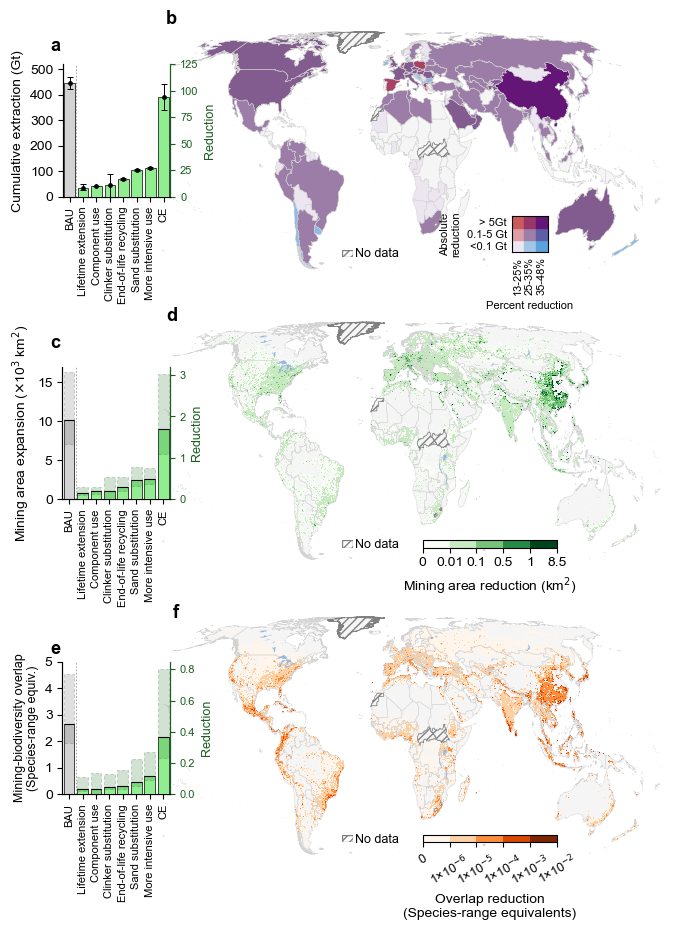

In [42]:
RED_AX = '#1b5e20'   # colour tying the right axis to the green reduction bars

fig = plt.figure(figsize=(7, 9), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial'

# ---- panel a/b : BAU total (left) + extraction reductions from 0 (right) ----
ax1 = plt.subplot(3, 1, 1, projection=ccrs.EckertIV())
draw_the_background(ax1)
world_map_eck4.plot(column='group_9', cmap=custom_cmap5, edgecolor='none', lw=0.1, ax=ax1)
draw_the_patch(ax1, 3, colorlist_5)

ax1_1 = ax1.inset_axes([-0.12, 0.30, 0.20, 0.55])
axR1 = draw_fig2_bar(extraction_reduction, ax1_1, uncertainty='errorbar')
ax1_1.set_ylim(0, 520); ax1_1.set_yticks([0, 100, 200, 300, 400, 500])
ax1_1.set_ylabel('Cumulative extraction (Gt)')
axR1.set_ylim(0, 125); axR1.set_yticks([0, 25, 50, 75, 100, 125])
axR1.set_ylabel('Reduction', color=RED_AX, fontsize=9)
axR1.tick_params(axis='y', colors=RED_AX, labelsize=8); axR1.spines['right'].set_color(RED_AX)
ax1_1.set_xticklabels(xtick_labels, fontsize=8, rotation=90)

# ---- panel c/d : BAU total (left) + mining-area reductions from 0 (right) ----
ax2 = plt.subplot(3, 1, 2, projection=ccrs.EckertIV())
ax2.add_feature(cf.LAKES, zorder=20)
draw_the_background(ax2)
norm_MA_50km = BoundaryNorm([0, 0.01, 0.1, 0.5, 1, 8.5], 256)
im1 = ax2.imshow(np.where(mining_area_reduction_CE_50km, mining_area_reduction_CE_50km, np.nan), cmap='Greens', interpolation='nearest', norm=norm_MA_50km, origin='upper', extent=display_extent_50km, zorder=5, alpha=1.0)

cax2_1 = ax2.inset_axes([0.55, 0.05, 0.25, 0.03])
cbar2_1 = fig.colorbar(im1, cax=cax2_1, orientation='horizontal', label='Mining area reduction (km$^{2}$)')
formatter = FuncFormatter(lambda x, _: f'{x:.2g}')
cbar2_1.ax.xaxis.set_major_formatter(formatter)
cbar2_1.formatter = formatter
cbar2_1.update_ticks()

ax2_1 = ax2.inset_axes([-0.12, 0.25, 0.20, 0.55])
axR2 = draw_fig2_bar(mining_area_reduction / 1e3, ax2_1, uncertainty='band')
ax2_1.set_ylim(0, 17); ax2_1.set_yticks([0, 5, 10, 15])
ax2_1.set_ylabel('Mining area expansion ($\\times$10$^{3}$ km$^{2}$)')
axR2.set_ylim(0, 3.2); axR2.set_yticks([0, 1, 2, 3])
axR2.set_ylabel('Reduction', color=RED_AX, fontsize=9)
axR2.tick_params(axis='y', colors=RED_AX, labelsize=8); axR2.spines['right'].set_color(RED_AX)
ax2_1.set_xticklabels(xtick_labels, fontsize=8, rotation=90)

# ---- panel e/f : BAU total (left) + overlap reductions from 0 (right) ----
ax3 = plt.subplot(3, 1, 3, projection=ccrs.EckertIV())
ax3.add_feature(cf.LAKES, zorder=20)
draw_the_background(ax3)
norm_ASR_50km = BoundaryNorm([0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2], 256)
im3 = ax3.imshow(np.where(overlap_reduction_CE_50km, overlap_reduction_CE_50km, np.nan), cmap='Oranges', interpolation='nearest', norm=norm_ASR_50km, origin='upper', extent=display_extent_50km, zorder=5, alpha=1.0)

cax3_1 = ax3.inset_axes([0.55, 0.05, 0.25, 0.03])
cbar3_1 = fig.colorbar(im3, cax=cax3_1, orientation='horizontal', label='Overlap reduction\n(Species-range equivalents)')
cbar3_1.ax.xaxis.set_major_formatter(FuncFormatter(sci_fmt))
for label in cbar3_1.ax.get_xticklabels():
    label.set_rotation(30)
    label.set_fontsize(9)

ax3_1 = ax3.inset_axes([-0.12, 0.25, 0.20, 0.55])
axR3 = draw_fig2_bar(mining_biodiversity_overlap_reduction, ax3_1, uncertainty='band')
ax3_1.set_ylim(0, 5); ax3_1.set_yticks([0, 1, 2, 3, 4, 5])
ax3_1.set_ylabel('Mining-biodiversity overlap\n(Species-range equiv.)', fontsize=9)
axR3.set_ylim(0, 0.85); axR3.set_yticks([0, 0.2, 0.4, 0.6, 0.8])
axR3.set_ylabel('Reduction', color=RED_AX, fontsize=9)
axR3.tick_params(axis='y', colors=RED_AX, labelsize=8); axR3.spines['right'].set_color(RED_AX)
ax3_1.set_xticklabels(xtick_labels, fontsize=8, rotation=90)

font_size = 13
fig.text(0.085, 0.97, 'a', fontdict={'size': font_size, 'weight': 'semibold'})
fig.text(0.25, 1.00, 'b', fontdict={'size': font_size, 'weight': 'semibold'})
fig.text(0.085, 0.64, 'c', fontdict={'size': font_size, 'weight': 'semibold'})
fig.text(0.25, 0.67, 'd', fontdict={'size': font_size, 'weight': 'semibold'})
fig.text(0.085, 0.30, 'e', fontdict={'size': font_size, 'weight': 'semibold'})
fig.text(0.26, 0.34, 'f', fontdict={'size': font_size, 'weight': 'semibold'})

plt.show()
fig.savefig(FIGURES / 'Figure-2.jpg', dpi=600, bbox_inches='tight')

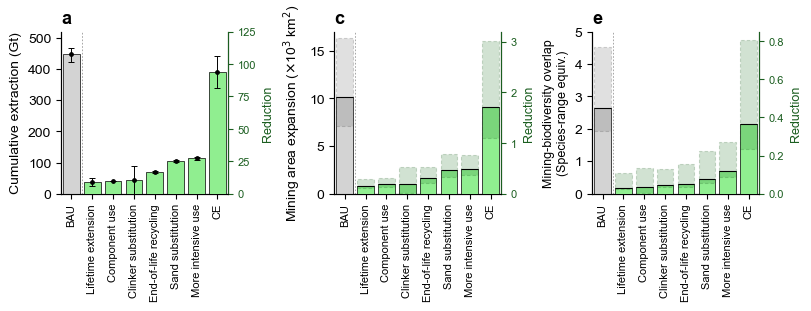

In [43]:
fig = plt.figure(figsize=(8, 3), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial'

ax1_1 = plt.subplot(1, 3, 1)
axR1 = draw_fig2_bar(extraction_reduction, ax1_1, uncertainty='errorbar')
ax1_1.set_ylim(0, 520); ax1_1.set_yticks([0, 100, 200, 300, 400, 500])
ax1_1.set_ylabel('Cumulative extraction (Gt)')
axR1.set_ylim(0, 125); axR1.set_yticks([0, 25, 50, 75, 100, 125])
axR1.set_ylabel('Reduction', color=RED_AX, fontsize=9)
axR1.tick_params(axis='y', colors=RED_AX, labelsize=8); axR1.spines['right'].set_color(RED_AX)
ax1_1.set_xticklabels(xtick_labels, fontsize=8, rotation=90)
ax1_1.set_title('a', loc='left', fontdict={'size': font_size, 'weight': 'semibold'})

ax2_1 = plt.subplot(1, 3, 2)
axR2 = draw_fig2_bar(mining_area_reduction / 1e3, ax2_1, uncertainty='band')
ax2_1.set_ylim(0, 17); ax2_1.set_yticks([0, 5, 10, 15])
ax2_1.set_ylabel('Mining area expansion ($\\times$10$^{3}$ km$^{2}$)')
axR2.set_ylim(0, 3.2); axR2.set_yticks([0, 1, 2, 3])
axR2.set_ylabel('Reduction', color=RED_AX, fontsize=9)
axR2.tick_params(axis='y', colors=RED_AX, labelsize=8); axR2.spines['right'].set_color(RED_AX)
ax2_1.set_xticklabels(xtick_labels, fontsize=8, rotation=90)
ax2_1.set_title('c', loc='left', fontdict={'size': font_size, 'weight': 'semibold'})

ax3_1 = plt.subplot(1, 3, 3)
axR3 = draw_fig2_bar(mining_biodiversity_overlap_reduction, ax3_1, uncertainty='band')
ax3_1.set_ylim(0, 5); ax3_1.set_yticks([0, 1, 2, 3, 4, 5])
ax3_1.set_ylabel('Mining-biodiversity overlap\n(Species-range equiv.)', fontsize=9)
axR3.set_ylim(0, 0.85); axR3.set_yticks([0, 0.2, 0.4, 0.6, 0.8])
axR3.set_ylabel('Reduction', color=RED_AX, fontsize=9)
axR3.tick_params(axis='y', colors=RED_AX, labelsize=8); axR3.spines['right'].set_color(RED_AX)
ax3_1.set_xticklabels(xtick_labels, fontsize=8, rotation=90)
ax3_1.set_title('e', loc='left', fontdict={'size': font_size, 'weight': 'semibold'})

plt.show()
fig.savefig(FIGURES / f'Figure-2-sub.jpg', dpi=600, bbox_inches='tight')